# Análisis de Big Data con Apache Hadoop y MapReduce

**Actividad:** Informe técnico – Análisis de Big Data
**Entorno:** Google Colab (Hadoop 3.3.6 en modo *standalone* + Hadoop Streaming con Python)

---

## Objetivo

Analizar un conjunto de 50.000 reclamaciones de seguros mediante el paradigma MapReduce sobre Apache Hadoop, documentando el entorno, los scripts, la ejecución de los procesos, los resultados y su interpretación técnica.

## Índice

1. Marco conceptual (qué es MapReduce y qué papel juega Hadoop)
2. Instalación y configuración del entorno
3. Dataset
4. Cómo funciona Hadoop Streaming
5. Job 1: estadísticas de reclamaciones por ramo (mapper + reducer)
6. Prueba local del job (simulación del pipeline)
7. Ejecución del Job 1 en Hadoop
8. Lectura de resultados y *counters*
9. Job 2: siniestros por mes, con *combiner*
10. Visualización
11. Validación contra pandas
12. Interpretación técnica y toma de decisiones
13. Standalone vs. clúster real
14. Conclusiones
15. Referencias (APA 7)

## 1. Marco conceptual

### 1.1 ¿Qué es MapReduce?

MapReduce es un **paradigma de programación para procesar grandes volúmenes de datos de forma distribuida**. La idea central: en lugar de traer los datos a un programa, se **lleva el programa a los datos**, y se divide el trabajo en piezas pequeñas e independientes que pueden ejecutarse en paralelo en muchas máquinas.

Un job de MapReduce pasa por tres fases:

| Fase | Qué hace | Quién la escribe |
|---|---|---|
| **Map** | Lee cada registro de entrada y emite pares `(clave, valor)`. Corre en paralelo sobre pedazos (*splits*) del archivo. | Tú (mapper) |
| **Shuffle & Sort** | El framework agrupa todos los valores que comparten la misma clave y los ordena por clave. Mueve los datos entre nodos. | Hadoop (automático) |
| **Reduce** | Recibe cada clave con todos sus valores y los agrega (suma, promedio, máximo, etc.). | Tú (reducer) |

```
 Entrada          MAP                SHUFFLE & SORT              REDUCE            Salida
┌────────┐   ┌───────────┐       ┌──────────────────┐       ┌───────────┐     ┌────────┐
│ split1 │──▶│ (k1,v)(k2,v)│──┐   │ k1 → [v, v, v]   │──────▶│ k1 → agg  │────▶│        │
│ split2 │──▶│ (k2,v)(k1,v)│──┼──▶│ k2 → [v, v]      │──────▶│ k2 → agg  │────▶│ part-* │
│ split3 │──▶│ (k1,v)(k3,v)│──┘   │ k3 → [v]         │──────▶│ k3 → agg  │────▶│        │
└────────┘   └───────────┘       └──────────────────┘       └───────────┘     └────────┘
```

**Ejemplo mental:** contar palabras. El mapper emite `(palabra, 1)` por cada palabra; el shuffle junta todos los `1` de cada palabra; el reducer los suma.

### 1.2 ¿Qué papel juega Apache Hadoop?

Hadoop es el **ecosistema** que hace posible ejecutar MapReduce a escala. Sus componentes principales:

- **HDFS (Hadoop Distributed File System):** almacenamiento distribuido. Divide los archivos en bloques (128 MB por defecto) y los replica en varios nodos para tolerar fallos.
- **YARN (Yet Another Resource Negotiator):** administra los recursos del clúster (CPU/memoria) y programa las tareas. El *ResourceManager* coordina y los *NodeManagers* ejecutan contenedores en cada nodo.
- **MapReduce:** el motor de procesamiento que ejecuta los jobs sobre YARN, leyendo y escribiendo en HDFS.
- **Hadoop Common:** utilidades compartidas por los demás módulos.

Características que lo hacen valioso en Big Data: **escalabilidad horizontal** (agregas máquinas), **tolerancia a fallos** (si una tarea falla se reejecuta en otro nodo, y los datos están replicados) y **localidad de datos** (se intenta ejecutar el map en el nodo donde ya está el bloque).

### 1.3 Procesamiento → análisis → visualización

Estos tres pasos son una cadena:

1. **Procesamiento:** MapReduce reduce millones de registros crudos a resultados agregados y manejables.
2. **Análisis:** se interpretan esos agregados (comparaciones, tendencias, anomalías).
3. **Visualización:** se presentan en gráficas para que quien toma decisiones los entienda rápido.

Sin el primer paso no puedes analizar a esta escala; sin el último, el análisis no llega a quien decide.

### 1.4 Importancia para la toma de decisiones

Una organización (por ejemplo, una aseguradora) puede usar este tipo de procesamiento para saber qué línea de negocio concentra más costo, cuándo se disparan los siniestros o qué ciudades requieren más capacidad de atención. Los datos agregados convierten volumen en decisiones: asignación de presupuesto, ajuste de primas, dimensionamiento de equipos.

## 2. Instalación y configuración del entorno

Colab es una máquina Linux (Ubuntu) temporal. Cada vez que se reinicia el entorno, **se pierde todo lo instalado**, por eso la configuración se deja en celdas reproducibles.

Hadoop está escrito en Java, por lo que se requiere:

1. **JDK 8** (Java Development Kit). Hadoop 3.3.x soporta oficialmente Java 8 y 11; se utilizó la 8.
2. El **binario de Hadoop 3.3.6**, que se descarga de `archive.apache.org` (el espejo `dlcdn` solo conserva versiones recientes y suele dar 404 con versiones anteriores).

**Qué hace cada línea de la siguiente celda:**

- `apt-get update -qq`: actualiza el índice de paquetes. En Colab es necesario porque el índice que trae la máquina puede estar desactualizado y apuntar a archivos que ya no existen en los servidores de Ubuntu (error 404), lo que hace fallar la instalación de Java.
- `apt-get install -y openjdk-8-jdk-headless -qq`: instala Java. `-y` acepta automáticamente, `-qq` reduce el ruido y `headless` instala la versión sin interfaz gráfica (más liviana).
- `wget -q ...`: descarga el `.tar.gz` de Hadoop (pesa cerca de 700 MB, tarda un par de minutos).
- `tar -xzf ...`: descomprime el archivo en `/content/hadoop-3.3.6`.

In [16]:
!wget -q https://archive.apache.org/dist/hadoop/common/hadoop-3.3.6/hadoop-3.3.6.tar.gz
!tar -xzf hadoop-3.3.6.tar.gz
!ls hadoop-3.3.6

bin  include  libexec	      licenses-binary  NOTICE-binary  README.txt  share
etc  lib      LICENSE-binary  LICENSE.txt      NOTICE.txt     sbin


### 2.1 Variables de entorno y verificación

Hadoop necesita saber dónde está Java y dónde está él mismo:

- `JAVA_HOME`: carpeta del JDK instalado. La celda la **detecta con `glob`** en lugar de escribirla a mano; si Java no se instaló bien, el `assert` lo indica de inmediato en vez de dejar que el error aparezca después dentro del job.
- `HADOOP_HOME`: carpeta donde descomprimimos Hadoop.
- `PATH`: se le agrega `HADOOP_HOME/bin` para poder escribir simplemente `hadoop` en la terminal.

Las variables se definen con `os.environ` en Python. Los comandos `!` de las celdas siguientes **heredan** estas variables, así que no hace falta redefinirlas.

`hadoop version` es la **primera evidencia técnica**: demuestra que Hadoop quedó instalado y funcionando.

In [17]:
import os, glob

# Detecta la carpeta real de Java 8 (evita rutas escritas a mano que pueden no existir)
rutas_java = glob.glob("/usr/lib/jvm/java-8-openjdk-*")
assert rutas_java, "No se encontró Java 8. Vuelve a ejecutar la celda de instalación y revisa sus errores."

os.environ["JAVA_HOME"] = rutas_java[0]
os.environ["HADOOP_HOME"] = "/content/hadoop-3.3.6"
os.environ["PATH"] += f":{os.environ['HADOOP_HOME']}/bin"
print("JAVA_HOME =", os.environ["JAVA_HOME"])

!$JAVA_HOME/bin/java -version
!hadoop version

JAVA_HOME = /usr/lib/jvm/java-8-openjdk-amd64
openjdk version "1.8.0_512"
OpenJDK Runtime Environment (build 1.8.0_512-8u512-b09~us1-0ubuntu1~24.04.1-b09)
OpenJDK 64-Bit Server VM (build 25.512-b09, mixed mode)
Hadoop 3.3.6
Source code repository https://github.com/apache/hadoop.git -r 1be78238728da9266a4f88195058f08fd012bf9c
Compiled by ubuntu on 2023-06-18T08:22Z
Compiled on platform linux-x86_64
Compiled with protoc 3.7.1
From source with checksum 5652179ad55f76cb287d9c633bb53bbd
This command was run using /content/hadoop-3.3.6/share/hadoop/common/hadoop-common-3.3.6.jar


## 3. Dataset

### 3.1 Generación del dataset simulado

Para que el cuaderno sea 100 % reproducible, generamos un archivo CSV con **50.000 reclamaciones** de una aseguradora ficticia. Es un volumen pequeño para Hadoop real, pero suficiente para ver todo el flujo (en un clúster, la misma lógica escala a miles de millones de filas sin cambiar el código del mapper y el reducer).

**Columnas del CSV:**

| # | Columna | Descripción |
|---|---|---|
| 0 | `id_siniestro` | Identificador único |
| 1 | `fecha` | Fecha del siniestro (`AAAA-MM-DD`) |
| 2 | `ciudad` | Ciudad donde ocurrió |
| 3 | `ramo` | Línea de negocio (Motos, Mascotas, Salud, Hogar) |
| 4 | `cobertura` | Tipo de cobertura afectada |
| 5 | `estado` | Aprobado, Rechazado o En revisión |
| 6 | `valor_reclamado` | Monto reclamado en COP |

**Detalles de la celda:**

- `np.random.default_rng(42)`: generador aleatorio con **semilla fija**, de modo que los datos generados son siempre los mismos.
- Los valores usan una distribución **log-normal** (muchos montos pequeños y pocos muy altos), que es lo típico en seguros.
- Se inyectan **50 filas dañadas a propósito** (valor vacío o texto) para demostrar cómo el mapper se defiende de datos sucios y cómo reportarlo con un *counter* personalizado.
- El archivo se guarda en `data/siniestros.csv`.

In [18]:
import numpy as np
import pandas as pd

os.makedirs("data", exist_ok=True)
rng = np.random.default_rng(42)
N = 50_000

ramos = ["Motos", "Mascotas", "Salud", "Hogar"]
prob_ramo = [0.40, 0.20, 0.25, 0.15]
# (mu, sigma) de la log-normal por ramo -> define el monto típico de cada línea
params = {"Motos": (13.6, 0.8), "Mascotas": (12.2, 0.6),
          "Salud": (13.9, 1.0), "Hogar": (13.3, 0.9)}

coberturas = {
    "Motos": ["Pérdida total", "Daños", "Responsabilidad civil"],
    "Mascotas": ["Consulta veterinaria", "Cirugía", "Vacunación"],
    "Salud": ["Hospitalización", "Urgencias", "Medicamentos"],
    "Hogar": ["Incendio", "Robo", "Daños por agua"],
}
ciudades = ["Bogotá", "Medellín", "Cali", "Barranquilla", "Bucaramanga"]
prob_ciudad = [0.38, 0.22, 0.17, 0.13, 0.10]

ramo = rng.choice(ramos, size=N, p=prob_ramo)
ciudad = rng.choice(ciudades, size=N, p=prob_ciudad)
cobertura = [rng.choice(coberturas[r]) for r in ramo]
estado = rng.choice(["Aprobado", "Rechazado", "En revisión"], size=N, p=[0.70, 0.18, 0.12])
valor = np.array([rng.lognormal(*params[r]) for r in ramo]).round(0)

# fechas 2024-2025 con estacionalidad: más siniestros en meses 6-7 y 11-12
dias = pd.date_range("2024-01-01", "2025-12-31")
peso = np.array([1.5 if d.month in (6, 7, 11, 12) else 1.0 for d in dias])
fecha = rng.choice(dias, size=N, p=peso / peso.sum())

df = pd.DataFrame({
    "id_siniestro": [f"S{i:06d}" for i in range(1, N + 1)],
    "fecha": pd.to_datetime(fecha).strftime("%Y-%m-%d"),
    "ciudad": ciudad, "ramo": ramo, "cobertura": cobertura,
    "estado": estado, "valor_reclamado": valor,
})

# 50 filas "sucias" para probar la robustez del mapper
sucias = rng.choice(N, size=50, replace=False)
df["valor_reclamado"] = df["valor_reclamado"].astype(object)
df.loc[sucias[:25], "valor_reclamado"] = ""
df.loc[sucias[25:], "valor_reclamado"] = "N/A"

df.to_csv("data/siniestros.csv", index=False)
print(f"Filas generadas: {len(df):,}")
df.head()

Filas generadas: 50,000


,id_siniestro,fecha,ciudad,ramo,cobertura,estado,valor_reclamado
0,S000001,2024-05-28,Barranquilla,Salud,Medicamentos,Aprobado,6236147.0
1,S000002,2025-10-15,Medellín,Mascotas,Vacunación,Aprobado,122018.0
2,S000003,2025-06-08,Cali,Hogar,Daños por agua,Aprobado,803532.0
3,S000004,2024-11-23,Bogotá,Salud,Medicamentos,Aprobado,2295661.0
4,S000005,2024-06-03,Medellín,Motos,Responsabilidad civil,Rechazado,1677913.0


### 3.2 Exploración rápida con pandas

Antes de procesar, conviene conocer los datos. Esta celda muestra tipos, nulos y estadísticas básicas. Nota: pandas aquí es solo para **explorar y validar**; el procesamiento principal del análisis se hace con MapReduce.

In [19]:
explorar = pd.read_csv("data/siniestros.csv")
print(explorar.info())
print("\nFilas por ramo:")
print(explorar["ramo"].value_counts())
print("\nTamaño del archivo:")
!ls -lh data/siniestros.csv

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_siniestro     50000 non-null  object 
 1   fecha            50000 non-null  object 
 2   ciudad           50000 non-null  object 
 3   ramo             50000 non-null  object 
 4   cobertura        50000 non-null  object 
 5   estado           50000 non-null  object 
 6   valor_reclamado  49950 non-null  float64
dtypes: float64(1), object(6)
memory usage: 2.7+ MB
None

Filas por ramo:
ramo
Motos       19864
Salud       12724
Mascotas     9983
Hogar        7429
Name: count, dtype: int64

Tamaño del archivo:
-rw-r--r-- 1 root root 3.2M Nov 14 02:25 data/siniestros.csv


## 4. Cómo funciona Hadoop Streaming

Hadoop nativo se programa en **Java**. **Hadoop Streaming** es una utilidad (un `.jar` incluido con Hadoop) que permite escribir el mapper y el reducer en **cualquier lenguaje** que lea de `stdin` y escriba en `stdout`. Nosotros usaremos Python.

**El contrato es simple:**

- **Mapper:** lee líneas de `stdin` (un registro por línea) y escribe líneas `clave<TAB>valor` en `stdout`.
- **Shuffle & sort:** Hadoop ordena todas las líneas del mapper por clave.
- **Reducer:** lee de `stdin` las líneas **ya ordenadas por clave** y escribe el resultado en `stdout`. Como llegan ordenadas, todas las líneas de una misma clave vienen consecutivas; así el reducer puede agrupar sin guardar todo en memoria.

**Counters personalizados:** si el script escribe en `stderr` una línea con formato `reporter:counter:<grupo>,<nombre>,<incremento>`, Hadoop la interpreta como un contador y lo suma en el reporte final. Lo usaremos para contar filas inválidas.

Esto permite probar los scripts **sin Hadoop** con un pipe de Unix (sección 6), porque `cat | mapper | sort | reducer` es exactamente el mismo flujo en miniatura.

## 5. Job 1: estadísticas de reclamaciones por ramo

**Pregunta de negocio:** ¿cuántas reclamaciones, qué monto total, qué promedio y qué máximo tiene cada ramo?

**Diseño:**

- **Clave:** `ramo`
- **Valor:** `valor_reclamado`
- **Mapper:** por cada fila válida emite `ramo \t valor`.
- **Reducer:** por cada ramo calcula `n`, `total`, `promedio` y `máximo`.

### 5.1 Mapper

`%%writefile mapper_ramo.py` es un *magic* de Jupyter: en vez de ejecutar la celda, **guarda su contenido como archivo**. Así el script queda en disco para que Hadoop lo use y, a la vez, visible en el notebook como evidencia.

**Paso a paso del código:**

1. `csv.reader(sys.stdin)`: lee la entrada estándar como CSV (maneja comillas y comas internas, mejor que `split(",")`).
2. Se **omite el encabezado** (la fila cuyo primer campo es `id_siniestro`).
3. Se extraen `ramo` (índice 3) y `valor` (índice 6, convertido a `float`).
4. Si falla (campo vacío, `N/A`, fila corta), se incrementa el *counter* `Calidad,filas_invalidas` y se sigue con la siguiente fila.
5. `print(f"{ramo}\t{valor}")`: emite el par clave-valor separado por tabulador.

In [20]:
%%writefile mapper_ramo.py
#!/usr/bin/env python3
"""Mapper Job 1: emite (ramo, valor_reclamado) por cada reclamación válida."""
import sys
import csv

lector = csv.reader(sys.stdin)
for fila in lector:
    # saltar líneas vacías y el encabezado
    if not fila or fila[0] == "id_siniestro":
        continue
    try:
        ramo = fila[3]
        valor = float(fila[6])
    except (IndexError, ValueError):
        # counter personalizado: Hadoop lo suma en el reporte final
        sys.stderr.write("reporter:counter:Calidad,filas_invalidas,1\n")
        continue
    print(f"{ramo}\t{valor}")

Overwriting mapper_ramo.py


### 5.2 Reducer

Recuerda que Hadoop entrega las líneas **ordenadas por clave**. Por eso usamos `itertools.groupby`, que agrupa líneas consecutivas con la misma clave.

**Paso a paso:**

1. Se define `parsear()`, un generador que convierte cada línea en `(clave, valor_float)`.
2. `groupby(parsear(), key=lambda x: x[0])` produce, para cada ramo, un iterador con todos sus valores.
3. Se recorre ese iterador **una sola vez** acumulando `n`, `total` y `maximo` (no se guardan todos los valores en memoria; por eso escala).
4. Se imprime `ramo \t n \t total \t promedio \t máximo`.

In [21]:
%%writefile reducer_ramo.py
#!/usr/bin/env python3
"""Reducer Job 1: por ramo calcula n, total, promedio y máximo."""
import sys
from itertools import groupby

def parsear(entrada):
    for linea in entrada:
        linea = linea.rstrip("\n")
        if not linea:
            continue
        clave, valor = linea.split("\t")
        yield clave, float(valor)

for ramo, grupo in groupby(parsear(sys.stdin), key=lambda x: x[0]):
    n = 0
    total = 0.0
    maximo = float("-inf")
    for _, valor in grupo:
        n += 1
        total += valor
        maximo = max(maximo, valor)
    print(f"{ramo}\t{n}\t{total:.2f}\t{total / n:.2f}\t{maximo:.2f}")

Overwriting reducer_ramo.py


## 6. Prueba local del job (sin Hadoop)

Antes de lanzar Hadoop conviene verificar que el mapper y el reducer funcionan. El pipeline de Unix simula las tres fases:

```
cat data/siniestros.csv | python3 mapper_ramo.py | sort | python3 reducer_ramo.py
```

- `cat ... |` → entrega el archivo al mapper por `stdin` (fase de entrada).
- `python3 mapper_ramo.py` → fase **Map**.
- `sort` → simula el **Shuffle & Sort**: ordena por clave.
- `python3 reducer_ramo.py` → fase **Reduce**.

`2>&1 | grep reporter` es solo para ver los counters que el mapper escribe en `stderr`; los mostramos aparte con un conteo.

**Resultado esperado:** una línea por ramo (4 en total). Si esto funciona, el job funcionará en Hadoop. Depurar aquí es mucho más rápido que depurar un job de Hadoop.

In [22]:
print("== Resultado del pipeline local ==")
!cat data/siniestros.csv | python3 mapper_ramo.py 2>/dev/null | sort | python3 reducer_ramo.py

print("\n== Filas inválidas detectadas por el mapper ==")
!cat data/siniestros.csv | python3 mapper_ramo.py 2>&1 >/dev/null | grep -c "reporter:counter"

== Resultado del pipeline local ==
Hogar	7422	6580777105.00	886658.19	23692101.00
Mascotas	9968	2375251105.00	238287.63	3785752.00
Motos	19846	22277036699.00	1122495.05	43777078.00
Salud	12714	22686220259.00	1784349.56	47876164.00

== Filas inválidas detectadas por el mapper ==
50


## 7. Ejecución del Job 1 en Hadoop

Ahora sí, el mismo código corre sobre el motor de MapReduce de Hadoop.

**Anatomía del comando:**

```
hadoop jar $HADOOP_HOME/share/hadoop/tools/lib/hadoop-streaming-3.3.6.jar \
  -D mapreduce.job.name="Job1_Estadisticas_por_Ramo" \
  -files mapper_ramo.py,reducer_ramo.py \
  -mapper "python3 mapper_ramo.py" \
  -reducer "python3 reducer_ramo.py" \
  -input data/siniestros.csv \
  -output output_job1
```

| Parte | Significado |
|---|---|
| `hadoop jar <jar>` | Ejecuta un `.jar`; aquí, la utilidad de Streaming. |
| `-D mapreduce.job.name=...` | Propiedad de configuración (nombre del job). Las opciones `-D` **deben ir primero**. |
| `-files` | Copia los scripts al *distributed cache*, para que cada tarea los tenga disponibles (en un clúster se distribuyen a todos los nodos). |
| `-mapper` / `-reducer` | Comando que ejecuta cada fase. |
| `-input` | Archivo o carpeta de entrada. |
| `-output` | Carpeta de salida. **No debe existir**: Hadoop falla si existe, para evitar sobrescribir resultados por error. De ahí el `rm -rf` previo. |

**Sobre las rutas:** como Colab corre Hadoop en modo *standalone*, el sistema de archivos por defecto es el **local** (`file:///`), no HDFS. Por eso `-input data/siniestros.csv` apunta a un archivo normal del disco.

**Sobre el log:** `2>&1 | tee logs/job1.log` envía a pantalla **y** a un archivo toda la salida (Hadoop escribe su log en `stderr`). Ese log contiene los *counters*, que son la evidencia técnica principal de la ejecución. Es normal ver advertencias como `Unable to load native-hadoop library`; no afectan la ejecución.

In [23]:
!mkdir -p logs
!rm -rf output_job1
!hadoop jar $HADOOP_HOME/share/hadoop/tools/lib/hadoop-streaming-3.3.6.jar \
  -D mapreduce.job.name="Job1_Estadisticas_por_Ramo" \
  -files mapper_ramo.py,reducer_ramo.py \
  -mapper "python3 mapper_ramo.py" \
  -reducer "python3 reducer_ramo.py" \
  -input data/siniestros.csv \
  -output output_job1 2>&1 | tee logs/job1.log | tail -n 15

# Verificación: si no existe _SUCCESS, el job falló y se muestra el final del log
!test -f output_job1/_SUCCESS && echo ">>> Job 1 terminó correctamente" || (echo ">>> Job 1 FALLÓ. Últimas líneas del log:"; tail -n 30 logs/job1.log)

		Total committed heap usage (bytes)=620756992
	Calidad
		filas_invalidas=50
	Shuffle Errors
		BAD_ID=0
		CONNECTION=0
		IO_ERROR=0
		WRONG_LENGTH=0
		WRONG_MAP=0
		WRONG_REDUCE=0
	File Input Format Counters 
		Bytes Read=3350596
	File Output Format Counters 
		Bytes Written=208
2026-11-14 02:26:05,864 INFO streaming.StreamJob: Output directory: output_job1
>>> Job 1 terminó correctamente


## 8. Lectura de resultados y *counters*

### 8.1 Contenido de la carpeta de salida

La carpeta `output_job1` contiene:

- `_SUCCESS`: archivo vacío que indica que el job terminó bien. Si no existe, algo falló.
- `part-00000`: resultado del reducer (uno por reducer; aquí hay uno).

In [24]:
!ls -la output_job1
print("\nramo \t n \t total \t promedio \t maximo")
!cat output_job1/part-*

total 20
drwxr-xr-x 2 root root 4096 Nov 14 02:26 .
drwxr-xr-x 1 root root 4096 Nov 14 02:26 ..
-rw-r--r-- 1 root root  196 Nov 14 02:26 part-00000
-rw-r--r-- 1 root root   12 Nov 14 02:26 .part-00000.crc
-rw-r--r-- 1 root root    0 Nov 14 02:26 _SUCCESS
-rw-r--r-- 1 root root    8 Nov 14 02:26 ._SUCCESS.crc

ramo 	 n 	 total 	 promedio 	 maximo
Hogar	7422	6580777105.00	886658.19	23692101.00
Mascotas	9968	2375251105.00	238287.63	3785752.00
Motos	19846	22277036699.00	1122495.05	43777078.00
Salud	12714	22686220259.00	1784349.56	47876164.00


### 8.2 Counters del job

Los *counters* son contadores que Hadoop mantiene automáticamente y sirven para **auditar** el procesamiento. Los más importantes:

| Counter | Qué indica |
|---|---|
| `Map input records` | Filas leídas por el mapper (incluye el encabezado). |
| `Map output records` | Pares clave-valor emitidos (debe ser menor: se descartan encabezado y filas inválidas). |
| `Reduce input groups` | Número de claves distintas (aquí: 4 ramos). |
| `Reduce input records` | Pares que recibió el reducer. |
| `Reduce output records` | Líneas escritas por el reducer. |
| `Calidad / filas_invalidas` | Nuestro counter personalizado. |

**Verificación de coherencia:** `Map input records − 1 (encabezado) − filas_invalidas = Map output records`.

In [25]:
!grep -E "Map input records|Map output records|Reduce input groups|Reduce input records|Reduce output records|filas_invalidas|Calidad" logs/job1.log

		Map input records=50001
		Map output records=49950
	Calidad
		filas_invalidas=50
		Reduce input groups=4
		Reduce input records=49950
		Reduce output records=4
		Map input records=50001
		Map output records=49950
		Reduce input groups=4
		Reduce input records=49950
		Reduce output records=4
	Calidad
		filas_invalidas=50


## 9. Job 2: siniestros por mes, con *combiner*

**Pregunta de negocio:** ¿cómo evoluciona la cantidad de siniestros mes a mes? ¿Hay estacionalidad?

**Diseño:**

- **Clave:** mes (`AAAA-MM`, los primeros 7 caracteres de la fecha).
- **Valor:** `1`.
- **Reducer:** suma los valores.

Es el clásico *word count* aplicado a negocio.

### 9.1 ¿Qué es un *combiner*?

Un **combiner** es un "mini-reducer" que corre **en el nodo del mapper, antes del shuffle**. Agrupa localmente los pares antes de enviarlos por la red.

Ejemplo: si un mapper emite 10.000 veces `("2024-06", 1)`, el combiner los convierte en un solo `("2024-06", 10000)` antes de moverlos. Menos datos en el shuffle = job más rápido y menos tráfico de red.

**Condición:** la operación debe ser **asociativa y conmutativa** (la suma lo es). Por eso aquí podemos usar **el mismo script** como combiner y como reducer. (En el Job 1, calcular un promedio directamente no permitiría usar el reducer como combiner sin rediseñarlo.)

En los counters del job aparecen `Combine input records` y `Combine output records`: la diferencia entre ambos es el ahorro.

In [26]:
%%writefile mapper_mes.py
#!/usr/bin/env python3
"""Mapper Job 2: emite (AAAA-MM, 1) por cada siniestro."""
import sys
import csv

for fila in csv.reader(sys.stdin):
    if not fila or fila[0] == "id_siniestro":
        continue
    try:
        mes = fila[1][:7]          # '2024-06-15' -> '2024-06'
        if len(mes) != 7:
            raise ValueError
    except (IndexError, ValueError):
        sys.stderr.write("reporter:counter:Calidad,fechas_invalidas,1\n")
        continue
    print(f"{mes}\t1")

Overwriting mapper_mes.py


In [27]:
%%writefile reducer_suma.py
#!/usr/bin/env python3
"""Reducer/Combiner genérico: suma los valores por clave."""
import sys
from itertools import groupby

def parsear(entrada):
    for linea in entrada:
        linea = linea.rstrip("\n")
        if linea:
            clave, valor = linea.split("\t")
            yield clave, int(valor)

for clave, grupo in groupby(parsear(sys.stdin), key=lambda x: x[0]):
    print(f"{clave}\t{sum(v for _, v in grupo)}")

Overwriting reducer_suma.py


### 9.2 Ejecución del Job 2

Es igual al Job 1, con una opción nueva: `-combiner "python3 reducer_suma.py"`. Nótese que `reducer_suma.py` aparece en `-files` una sola vez aunque se use dos veces.

In [28]:
!rm -rf output_job2
!hadoop jar $HADOOP_HOME/share/hadoop/tools/lib/hadoop-streaming-3.3.6.jar \
  -D mapreduce.job.name="Job2_Siniestros_por_Mes" \
  -files mapper_mes.py,reducer_suma.py \
  -mapper "python3 mapper_mes.py" \
  -combiner "python3 reducer_suma.py" \
  -reducer "python3 reducer_suma.py" \
  -input data/siniestros.csv \
  -output output_job2 2>&1 | tee logs/job2.log | tail -n 5

# Verificación: si no existe _SUCCESS, el job falló y se muestra el final del log
!test -f output_job2/_SUCCESS && echo ">>> Job 2 terminó correctamente" || (echo ">>> Job 2 FALLÓ. Últimas líneas del log:"; tail -n 30 logs/job2.log)

print("\n== Counters relevantes ==")
!grep -E "Map input records|Map output records|Combine input records|Combine output records|Reduce input records|Reduce output records" logs/job2.log
print("\n== Primeras líneas de la salida ==")
!head -n 6 output_job2/part-*

	File Input Format Counters 
		Bytes Read=3350596
	File Output Format Counters 
		Bytes Written=324
2026-11-14 02:26:13,564 INFO streaming.StreamJob: Output directory: output_job2
>>> Job 2 terminó correctamente

== Counters relevantes ==
		Map input records=50001
		Map output records=50000
		Combine input records=50000
		Combine output records=24
		Combine input records=0
		Combine output records=0
		Reduce input records=24
		Reduce output records=24
		Map input records=50001
		Map output records=50000
		Combine input records=50000
		Combine output records=24
		Reduce input records=24
		Reduce output records=24

== Primeras líneas de la salida ==
2024-01	1839
2024-02	1680
2024-03	1879
2024-04	1767
2024-05	1875
2024-06	2701


## 10. Visualización

Aquí cerramos la cadena **procesamiento → análisis → visualización**. Leemos las salidas de MapReduce (archivos separados por tabulador, sin encabezado) con pandas y graficamos con matplotlib. Los gráficos se guardan en `evidencias/`.

- `glob.glob("output_job1/part-*")` encuentra los archivos de resultado sin importar su nombre exacto.
- `names=[...]` asigna nombres de columna, porque la salida de Hadoop no trae encabezado.
- Se convierte el total a **millones de COP** para que el eje sea legible.

,ramo,n,total,promedio,maximo
3,Salud,12714,2.268622e+10,1784349.56,47876164.0
2,Motos,19846,2.227704e+10,1122495.05,43777078.0
0,Hogar,7422,6.580777e+09,886658.19,23692101.0
1,Mascotas,9968,2.375251e+09,238287.63,3785752.0


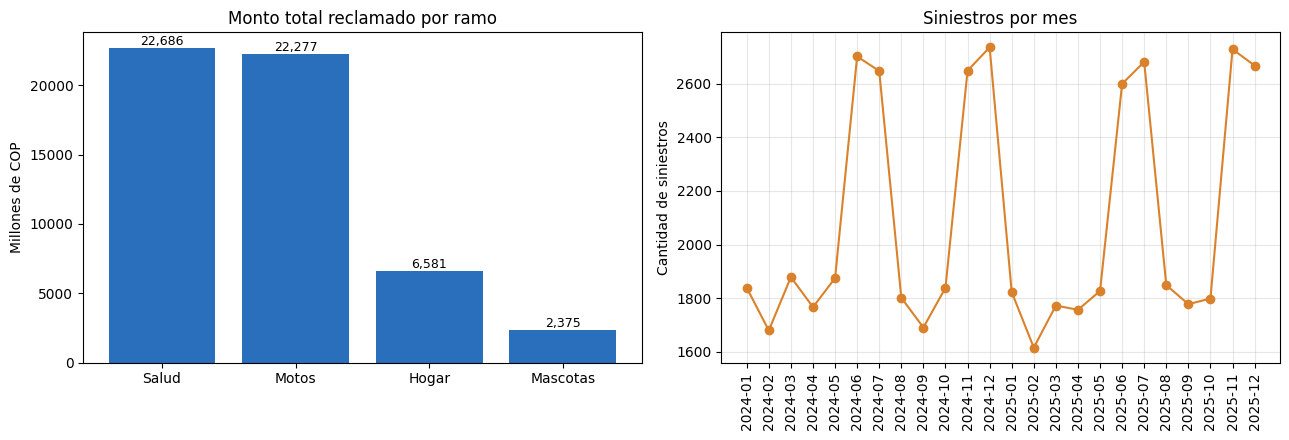

In [29]:
import glob
import matplotlib.pyplot as plt

os.makedirs("evidencias", exist_ok=True)

def leer_salida(carpeta, columnas):
    archivos = sorted(glob.glob(f"{carpeta}/part-*"))
    return pd.concat([pd.read_csv(a, sep="\t", header=None, names=columnas) for a in archivos])

res_ramo = leer_salida("output_job1", ["ramo", "n", "total", "promedio", "maximo"])
res_mes = leer_salida("output_job2", ["mes", "siniestros"]).sort_values("mes")

display(res_ramo.sort_values("total", ascending=False))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# Gráfica 1: monto total por ramo
orden = res_ramo.sort_values("total", ascending=False)
ax[0].bar(orden["ramo"], orden["total"] / 1e6, color="#2a6fbb")
ax[0].set_title("Monto total reclamado por ramo")
ax[0].set_ylabel("Millones de COP")
for i, v in enumerate(orden["total"] / 1e6):
    ax[0].text(i, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=9)

# Gráfica 2: siniestros por mes
ax[1].plot(res_mes["mes"], res_mes["siniestros"], marker="o", color="#d9822b")
ax[1].set_title("Siniestros por mes")
ax[1].set_ylabel("Cantidad de siniestros")
ax[1].tick_params(axis="x", rotation=90)
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("evidencias/resultados_mapreduce.png", dpi=150)
plt.show()

## 11. Validación contra pandas

¿Cómo sabemos que MapReduce calculó bien? **Recalculamos lo mismo con pandas** y comparamos. Es una buena práctica de ingeniería de datos y respalda la correcta ejecución de los jobs.

- `pd.to_numeric(..., errors="coerce")` convierte los valores inválidos (`""`, `"N/A"`) en `NaN`, y `dropna` los descarta, igual que hace el mapper.
- `np.isclose` compara decimales con tolerancia (evita falsos negativos por redondeo).

In [30]:
base = pd.read_csv("data/siniestros.csv", dtype=str)
base["valor"] = pd.to_numeric(base["valor_reclamado"], errors="coerce")
validas = base.dropna(subset=["valor"])

ref = validas.groupby("ramo")["valor"].agg(n="count", total="sum", promedio="mean", maximo="max").reset_index()
cmp_ = res_ramo.merge(ref, on="ramo", suffixes=("_mr", "_pd"))

ok_n = (cmp_["n_mr"] == cmp_["n_pd"]).all()
ok_total = np.isclose(cmp_["total_mr"], cmp_["total_pd"]).all()
ok_prom = np.isclose(cmp_["promedio_mr"], cmp_["promedio_pd"], atol=0.01).all()
ok_max = np.isclose(cmp_["maximo_mr"], cmp_["maximo_pd"]).all()

print(f"Conteo coincide:   {ok_n}")
print(f"Total coincide:    {ok_total}")
print(f"Promedio coincide: {ok_prom}")
print(f"Máximo coincide:   {ok_max}")

# Job 2
ref_mes = base.assign(mes=base["fecha"].str[:7]).groupby("mes").size().reset_index(name="siniestros_pd")
cmp_mes = res_mes.merge(ref_mes, on="mes")
print(f"Siniestros por mes coincide: {(cmp_mes['siniestros'] == cmp_mes['siniestros_pd']).all()}")

Conteo coincide:   True
Total coincide:    True
Promedio coincide: True
Máximo coincide:   True
Siniestros por mes coincide: True


## 12. Interpretación técnica y toma de decisiones

La siguiente celda calcula los hallazgos principales directamente a partir de los resultados de MapReduce. Se leen junto con las gráficas de la sección 10 y se desarrollan en las conclusiones.

La interpretación se organiza en torno a tres preguntas:

- ¿Qué ramo concentra más costo y qué lo explica: la cantidad de reclamaciones o el monto promedio?
- ¿El monto máximo se aleja mucho del promedio? Si es así, la distribución tiene cola larga (pocos siniestros muy costosos) y existe riesgo de severidad.
- ¿En qué meses se concentran los siniestros y qué acciones implica para la organización?

In [31]:
top_total = res_ramo.loc[res_ramo["total"].idxmax()]
top_prom = res_ramo.loc[res_ramo["promedio"].idxmax()]
top_n = res_ramo.loc[res_ramo["n"].idxmax()]
pico = res_mes.loc[res_mes["siniestros"].idxmax()]
valle = res_mes.loc[res_mes["siniestros"].idxmin()]
share = top_total["total"] / res_ramo["total"].sum() * 100
ratio = (res_ramo["maximo"] / res_ramo["promedio"]).max()

print("HALLAZGOS (calculados a partir de la salida de MapReduce)\n")
print(f"1. El ramo con mayor monto total es {top_total['ramo']}: "
      f"${top_total['total']/1e6:,.0f} M COP ({share:.1f}% del total reclamado).")
print(f"2. El ramo con más reclamaciones es {top_n['ramo']} ({int(top_n['n']):,} casos); "
      f"el de mayor monto promedio es {top_prom['ramo']} (${top_prom['promedio']:,.0f} COP).")
print(f"3. En algún ramo el máximo llega a {ratio:.0f} veces el promedio: cola larga, riesgo de severidad.")
print(f"4. Pico de siniestros: {pico['mes']} ({int(pico['siniestros']):,}); "
      f"valle: {valle['mes']} ({int(valle['siniestros']):,}).")
print(f"5. Calidad de datos: ver counter 'filas_invalidas' en logs/job1.log (50 filas dañadas inyectadas).")

HALLAZGOS (calculados a partir de la salida de MapReduce)

1. El ramo con mayor monto total es Salud: $22,686 M COP (42.1% del total reclamado).
2. El ramo con más reclamaciones es Motos (19,846 casos); el de mayor monto promedio es Salud ($1,784,350 COP).
3. En algún ramo el máximo llega a 39 veces el promedio: cola larga, riesgo de severidad.
4. Pico de siniestros: 2024-12 (2,735); valle: 2025-02 (1,616).
5. Calidad de datos: ver counter 'filas_invalidas' en logs/job1.log (50 filas dañadas inyectadas).


## 13. Standalone vs. clúster real

Lo que ejecutamos en Colab es MapReduce **real** (el mismo `.jar`, el mismo modelo de programación y los mismos counters), pero el **entorno** es distinto al de producción.

| Aspecto | Colab (modo standalone) | Clúster de producción |
|---|---|---|
| Almacenamiento | Sistema de archivos local | **HDFS** distribuido y replicado |
| Gestión de recursos | `LocalJobRunner` (un solo proceso JVM) | **YARN**: ResourceManager + NodeManagers |
| Paralelismo | Tareas map/reduce ejecutadas de forma secuencial/local | Cientos de contenedores en paralelo en distintos nodos |
| Tolerancia a fallos | No aplica | Reejecución de tareas y replicación de bloques |
| Localidad de datos | No aplica | El map corre donde está el bloque |
| Escala | Megabytes–gigabytes | Terabytes–petabytes |

**Lo importante:** el código del mapper y del reducer **no cambia** al pasar a un clúster; solo cambia dónde se ejecuta. Esa portabilidad es una de las ventajas del paradigma.

## 14. Conclusiones

1. **Paradigma.** MapReduce permitió reducir 50.000 registros a unos pocos resultados agregados dividiendo el trabajo en tres fases independientes: map, shuffle/sort y reduce. El código solo define qué se emite y cómo se agrega; la distribución, el ordenamiento por clave y la reejecución ante fallos las resuelve el framework. Por eso los mismos scripts podrían ejecutarse sin cambios en un clúster.

2. **Hadoop.** En Colab se trabajó en modo standalone, sin HDFS ni YARN, pero con el mismo `.jar` de Hadoop Streaming y los mismos counters que reporta un entorno real. Esto fue suficiente para validar la lógica del procesamiento. El paralelismo, la localidad de datos y la tolerancia a fallos solo se aprecian en un clúster, y esa es la principal diferencia con producción.

3. **Concentración del costo.** Salud y Motos reúnen el 83,4 % del monto reclamado (42,1 % y 41,3 %, cerca de 22.686 y 22.277 millones de COP). La causa es distinta en cada caso: Motos es el ramo con más reclamaciones (19.846, cerca del 40 % del total) y Salud tiene el monto promedio más alto (aproximadamente $1.784.350 COP) con menos casos (12.714). Hogar aporta el 12,2 % y Mascotas el 4,4 %.

4. **Severidad.** En todos los ramos el monto máximo supera ampliamente al promedio, entre 16 y 39 veces según el ramo, con Motos en el extremo. Es una distribución de cola larga: pocos siniestros muy costosos pesan mucho en el total, por lo que el promedio por sí solo no basta para estimar reservas o primas y convendría analizar percentiles.

5. **Estacionalidad.** Junio, julio, noviembre y diciembre promedian cerca de 2.676 siniestros al mes, frente a unos 1.787 en el resto del año (alrededor de un 50 % más), y el patrón se repite en 2024 y 2025. Como el dataset es simulado, esta estacionalidad fue incorporada al generarlo; lo relevante es que el Job 2 la recupera correctamente a partir de los datos crudos.

6. **Calidad de datos.** El counter personalizado `filas_invalidas` registró 50 filas dañadas. Los counters cuadran: 50.001 registros de entrada (incluido el encabezado) menos el encabezado y las 50 filas inválidas dan 49.950 registros emitidos por el mapper. El procesamiento distribuido debe tolerar registros dañados sin detener el job y dejar constancia de cuántos hubo.

7. **Optimización y validación.** En el Job 2 el combiner redujo de 50.000 a 24 los registros que llegaron al reducer (uno por mes), una disminución cercana al 99,95 % del volumen del shuffle. Además, los resultados de ambos jobs coincidieron con el cálculo equivalente en pandas, lo que respalda su correcto funcionamiento.

8. **Toma de decisiones.** Los resultados sugieren reforzar la capacidad de atención de siniestros y las reservas antes de los meses de mayor demanda, hacer seguimiento al costo de Salud y Motos por su peso en el monto total, y revisar mecanismos de control de severidad (límites por cobertura o reaseguro) para los casos de monto extremo.

9. **Limitaciones.** El entorno fue standalone, el dataset es simulado y de tamaño reducido, y las cifras dependen de la semilla usada. En producción habría que usar HDFS y YARN, y dimensionar el número de reducers según el volumen.

## 15. Referencias (APA 7.ª edición)

Apache Software Foundation. (2023). *MapReduce tutorial*. Apache Hadoop 3.3.6 documentation. https://hadoop.apache.org/docs/r3.3.6/hadoop-mapreduce-client/hadoop-mapreduce-client-core/MapReduceTutorial.html

Apache Software Foundation. (2023). *Hadoop streaming*. Apache Hadoop 3.3.6 documentation. https://hadoop.apache.org/docs/r3.3.6/hadoop-streaming/HadoopStreaming.html

Dean, J., & Ghemawat, S. (2004). MapReduce: Simplified data processing on large clusters. *Proceedings of the 6th Symposium on Operating Systems Design and Implementation (OSDI '04)*, 137–150. USENIX Association.

White, T. (2015). *Hadoop: The definitive guide* (4.ª ed.). O'Reilly Media.